# Global Zipfian Fit Accuracy Analysis

This notebook turns the original evaluation script into a small demo that asks: **how accurately does Zipf's law describe word frequencies in a public-domain novel such as *Pride and Prejudice*?**

It uses a curated subset of paragraphs from the cleaned *Pride and Prejudice* text, then fits the same two models as the original script: standard Zipf and Zipf-Mandelbrot. You will see the same maximum-likelihood fitting logic, the same goodness-of-fit metrics, and a final visualization comparing the two fits on the demo subset.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Core packages are pre-installed on Colab. Install them locally to match Colab's runtime.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
import numpy as np
import scipy.optimize as opt
from collections import Counter
import re
import json

import http.client
import urllib.request
from pathlib import Path
import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-624cdf-local-zipfian-curvature-as-narrative/main/round-2/evaluation-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


In [5]:
# Demo-scale configuration. The original script used the full cleaned novel.
N_PARAGRAPHS = 2
# Original full dataset equivalent: use all sampled paragraphs in mini_demo_data.json.
N_BINS = 2
# Original script value: 10
ZIPF_MANDELBROT_INITIAL_GUESS = [1.0, 1.0]
ZIPF_INITIAL_GUESS = [1.0]
OPTIMIZER_METHOD = "Nelder-Mead"

## Original helper functions

The next cell keeps the original script's tokenization, likelihood, fitting, and metric logic almost unchanged. The only notebook-specific edits are replacing a few hardcoded constants with config variables so the demo can be scaled up or down quickly.

In [6]:
def get_word_frequencies(text):
    words = re.findall(r'\b\w+\b', text.lower())
    counts = Counter(words)
    frequencies = sorted(counts.values(), reverse=True)
    return np.array(frequencies)

def log_likelihood(params, ranks, freqs):
    s, b = params
    if s <= 0 or b < 0:
        return 1e10  # Penalize invalid parameters

    # Probabilities
    probs = (ranks + b) ** (-s)
    probs /= np.sum(probs)

    # Log-likelihood: sum(freqs * log(probs))
    ll = np.sum(freqs * np.log(probs + 1e-10))
    return -ll # Minimize negative log-likelihood

def fit_zipf_mandelbrot(freqs):
    ranks = np.arange(1, len(freqs) + 1)
    # Initial guess: s=1, b=1
    result = opt.minimize(log_likelihood, ZIPF_MANDELBROT_INITIAL_GUESS, args=(ranks, freqs), method=OPTIMIZER_METHOD)
    return result.x

def fit_zipf(freqs):
    ranks = np.arange(1, len(freqs) + 1)
    # b is fixed to 0. Optimize only s.
    def ll_zipf(s, ranks, freqs):
        if s <= 0: return 1e10
        probs = ranks ** (-s)
        probs /= np.sum(probs)
        return -np.sum(freqs * np.log(probs + 1e-10))

    result = opt.minimize(ll_zipf, ZIPF_INITIAL_GUESS, args=(ranks, freqs), method=OPTIMIZER_METHOD)
    return result.x[0], 0.0

def calculate_ks(freqs, s, b):
    ranks = np.arange(1, len(freqs) + 1)
    # Theoretical frequencies
    probs = (ranks + b) ** (-s)
    probs /= np.sum(probs)

    # Cumulative distribution
    obs_cdf = np.cumsum(freqs) / np.sum(freqs)
    theo_cdf = np.cumsum(probs)

    return np.max(np.abs(obs_cdf - theo_cdf))

def calculate_aic_bic(ll, k, n):
    aic = 2 * k - 2 * ll
    bic = k * np.log(n) - 2 * ll
    return aic, bic

def calculate_r2(freqs, s, b):
    """R² on log-log rank-frequency space."""
    ranks = np.arange(1, len(freqs) + 1)
    probs = (ranks + b) ** (-s)
    probs /= np.sum(probs)
    theo_freqs = probs * np.sum(freqs)

    log_obs = np.log10(freqs)
    log_theo = np.log10(theo_freqs)

    ss_res = np.sum((log_obs - log_theo) ** 2)
    ss_tot = np.sum((log_obs - np.mean(log_obs)) ** 2)
    return 1 - ss_res / ss_tot

def residual_by_bin(freqs, s, b, n_bins=10):
    """Residual analysis binned by frequency (head/mid/tail)."""
    ranks = np.arange(1, len(freqs) + 1)
    probs = (ranks + b) ** (-s)
    probs /= np.sum(probs)
    theo_freqs = probs * np.sum(freqs)

    # Bin by rank (which correlates with frequency)
    bins = np.array_split(np.arange(len(freqs)), n_bins)
    residuals = []
    for i, bin_idx in enumerate(bins):
        obs_mean = np.mean(freqs[bin_idx])
        theo_mean = np.mean(theo_freqs[bin_idx])
        residuals.append({
            "bin": i,
            "rank_start": int(bin_idx[0] + 1),
            "rank_end": int(bin_idx[-1] + 1),
            "observed_mean": float(obs_mean),
            "fitted_mean": float(theo_mean),
            "residual": float(obs_mean - theo_mean)
        })
    return residuals

## Build the demo text

The original script reads the full cleaned novel from disk. In the notebook, we instead concatenate a small number of sampled paragraphs from `mini_demo_data.json` so the exact same fitting code can run locally now and from GitHub later.

In [7]:
available_paragraphs = len(data['paragraphs'])
selected_paragraphs = data['paragraphs'][:min(N_PARAGRAPHS, available_paragraphs)]
text = '\n\n'.join(item['text'] for item in selected_paragraphs)

print(f"Using {len(selected_paragraphs)} paragraphs out of {available_paragraphs} available in mini_demo_data.json.")
print(f"Word tokens in demo text: {len(re.findall(r'\b\w+\b', text.lower()))}")

Using 2 paragraphs out of 100 available in mini_demo_data.json.
Word tokens in demo text: 33


## Run the original evaluation logic

This cell mirrors the `main()` function from the script: compute word frequencies, fit both models, score them with log-likelihood, AIC/BIC, KS, and R², then package the results in the same general structure as the original JSON output.

In [8]:
freqs = get_word_frequencies(text)
n = np.sum(freqs)

# Fit Zipf-Mandelbrot
s_zm, b_zm = fit_zipf_mandelbrot(freqs)
# Fit Zipf
s_z, b_z = fit_zipf(freqs)

# Calculate Metrics
ranks = np.arange(1, len(freqs) + 1)

# Log-likelihoods
ll_zm = -log_likelihood([s_zm, b_zm], ranks, freqs)
ll_z = -log_likelihood([s_z, b_z], ranks, freqs)

aic_zm, bic_zm = calculate_aic_bic(ll_zm, 2, n)
aic_z, bic_z = calculate_aic_bic(ll_z, 1, n)

ks_zm = calculate_ks(freqs, s_zm, b_zm)
ks_z = calculate_ks(freqs, s_z, b_z)

r2_zm = calculate_r2(freqs, s_zm, b_zm)
r2_z = calculate_r2(freqs, s_z, b_z)

res_zm = residual_by_bin(freqs, s_zm, b_zm, n_bins=N_BINS)
res_z = residual_by_bin(freqs, s_z, b_z, n_bins=N_BINS)

# Create the schema-compliant output
results = {
    "metadata": {
        "evaluation_name": "Global Zipfian Fit Accuracy Analysis",
        "description": "Rigorous global MLE-based fitting of Zipf and Zipf-Mandelbrot models to a demo subset of Pride and Prejudice",
        "parameters": {
            "source_text": "mini_demo_data.json",
            "paragraphs_used": len(selected_paragraphs),
            "method": "Maximum Likelihood Estimation"
        }
    },
    "metrics_agg": {
        "zipf_mandelbrot_s": float(s_zm),
        "zipf_mandelbrot_b": float(b_zm),
        "zipf_mandelbrot_aic": float(aic_zm),
        "zipf_mandelbrot_bic": float(bic_zm),
        "zipf_mandelbrot_ks": float(ks_zm),
        "zipf_mandelbrot_r2": float(r2_zm),
        "zipf_s": float(s_z),
        "zipf_b": float(b_z),
        "zipf_aic": float(aic_z),
        "zipf_bic": float(bic_z),
        "zipf_ks": float(ks_z),
        "zipf_r2": float(r2_z),
        "aic_difference": float(aic_z - aic_zm),  # positive means ZM better
        "bic_difference": float(bic_z - bic_zm),
        "ks_improvement": float(ks_z - ks_zm)  # positive means ZM better
    },
    "datasets": [
        {
            "dataset": "pride_and_prejudice_demo",
            "examples": [
                {
                    "input": "Evaluate Zipf-Mandelbrot model fit on Pride and Prejudice word frequencies",
                    "output": "Model fit completed with MLE estimation",
                    "predict_s": str(s_zm),
                    "predict_b": str(b_zm),
                    "predict_aic": str(aic_zm),
                    "predict_bic": str(bic_zm),
                    "predict_ks": str(ks_zm),
                    "predict_r2": str(r2_zm),
                    "eval_ks": float(ks_zm),
                    "eval_r2": float(r2_zm),
                    "eval_aic": float(aic_zm),
                    "eval_bic": float(bic_zm),
                    "metadata_residuals_by_bin": json.dumps(res_zm)
                },
                {
                    "input": "Evaluate Zipf model fit on Pride and Prejudice word frequencies",
                    "output": "Model fit completed with MLE estimation",
                    "predict_s": str(s_z),
                    "predict_b": str(b_z),
                    "predict_aic": str(aic_z),
                    "predict_bic": str(bic_z),
                    "predict_ks": str(ks_z),
                    "predict_r2": str(r2_z),
                    "eval_ks": float(ks_z),
                    "eval_r2": float(r2_z),
                    "eval_aic": float(aic_z),
                    "eval_bic": float(bic_z),
                    "metadata_residuals_by_bin": json.dumps(res_z)
                }
            ]
        }
    ]
}

results['metrics_agg']

{'zipf_mandelbrot_s': 0.44386685669385206,
 'zipf_mandelbrot_b': 4.238492660550189e-08,
 'zipf_mandelbrot_aic': 210.7992981059253,
 'zipf_mandelbrot_bic': 213.79231322885826,
 'zipf_mandelbrot_ks': 0.029525299379920877,
 'zipf_mandelbrot_r2': 0.7842295111775266,
 'zipf_s': 0.4440429687499995,
 'zipf_b': 0.0,
 'zipf_aic': 208.7992969793959,
 'zipf_bic': 210.29580454086238,
 'zipf_ks': 0.02957124613416784,
 'zipf_r2': 0.7841621239278249,
 'aic_difference': -2.0000011265293836,
 'bic_difference': -3.4965086879958847,
 'ks_improvement': 4.5946754246961596e-05}

## Summarize and visualize the fitted models

The final cell turns the computed numbers into a quick demo view: a compact metric table, a rank-frequency plot, and residuals binned by rank. All values come directly from the fitting code above.

Model                     s        b          AIC          BIC       KS      R^2
------------------------------------------------------------------------------
Zipf-Mandelbrot       0.444    0.000       210.80       213.79    0.030    0.784
Zipf                  0.444    0.000       208.80       210.30    0.030    0.784


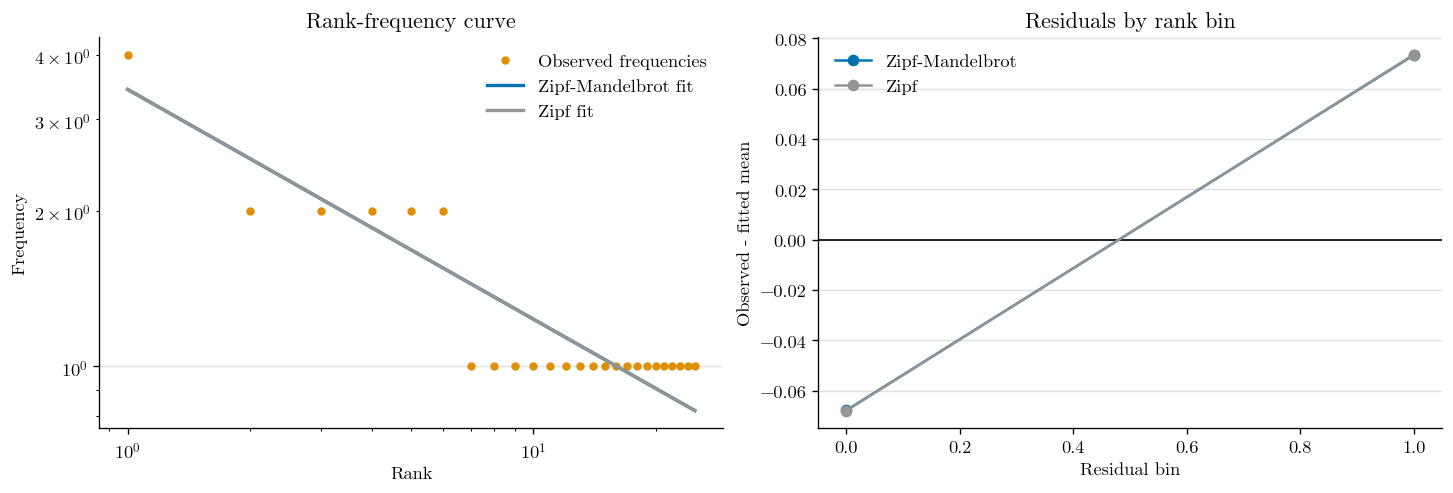

In [9]:
probs_zm = (ranks + b_zm) ** (-s_zm)
probs_zm /= np.sum(probs_zm)
theo_freqs_zm = probs_zm * np.sum(freqs)

probs_z = ranks ** (-s_z)
probs_z /= np.sum(probs_z)
theo_freqs_z = probs_z * np.sum(freqs)

print(f"{'Model':<18} {'s':>8} {'b':>8} {'AIC':>12} {'BIC':>12} {'KS':>8} {'R^2':>8}")
print('-' * 78)
print(f"{'Zipf-Mandelbrot':<18} {s_zm:>8.3f} {b_zm:>8.3f} {aic_zm:>12.2f} {bic_zm:>12.2f} {ks_zm:>8.3f} {r2_zm:>8.3f}")
print(f"{'Zipf':<18} {s_z:>8.3f} {b_z:>8.3f} {aic_z:>12.2f} {bic_z:>12.2f} {ks_z:>8.3f} {r2_z:>8.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].loglog(ranks, freqs, 'o', markersize=4, color=COLOURS['other_1'], label='Observed frequencies')
axes[0].loglog(ranks, theo_freqs_zm, color=COLOURS['method'], linewidth=2, label='Zipf-Mandelbrot fit')
axes[0].loglog(ranks, theo_freqs_z, color=COLOURS['baseline'], linewidth=2, label='Zipf fit')
axes[0].set_xlabel('Rank')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Rank-frequency curve')
axes[0].legend()

axes[1].axhline(0, color='black', linewidth=1)
axes[1].plot([item['bin'] for item in res_zm], [item['residual'] for item in res_zm], marker='o', color=COLOURS['method'], label='Zipf-Mandelbrot')
axes[1].plot([item['bin'] for item in res_z], [item['residual'] for item in res_z], marker='o', color=COLOURS['baseline'], label='Zipf')
axes[1].set_xlabel('Residual bin')
axes[1].set_ylabel('Observed - fitted mean')
axes[1].set_title('Residuals by rank bin')
axes[1].legend()

plt.show()

## Interpretation

On this demo subset, both models reproduce the familiar rank-frequency decay, but the comparison metrics and residual plot show which model tracks the data more closely. Lower AIC/BIC and KS, together with higher R², indicate the better fit. When Zipf-Mandelbrot has smaller residuals near the head of the distribution, it supports the artifact's main claim that adding curvature improves the global fit beyond standard Zipf's law.